# ICAIC Practice Problem — Which Signal Came First?

## Task

A factory records **temperature, vibration, and load** for each machine over **384 timesteps**. Each recording window contains two events, one early and one late. During each event, temperature and vibration each rise to a peak.

A pulse in the **load channel** marks the event you should classify. Predict which signal peaked first **within that marked event**. The other event may have a different peak order.

## Inputs and labels

- `X` has shape `[N, 384, 3]`, where `N` is the number of windows.
- The three channels are temperature, vibration, and load, in that order.
- `y` has shape `[N]` and contains one integer label per window.

| Label | Meaning for the marked event |
|---|---|
| `0` | Temperature peaks more than 3 timesteps before vibration. |
| `1` | Vibration peaks more than 3 timesteps before temperature. |
| `2` | The peaks are at most 3 timesteps apart, including exact ties. |

**Example.** The load pulse marks the late event. Temperature peaks at timestep 268 and vibration peaks at 270. They are 2 timesteps apart, so the label is `2`.

The underlying peak times and the marked event’s identity are hidden. Infer them from the recorded sensor values.

## Dataset splits

The starter code provides all three splits. Each split contains different machines, with different offsets and noise levels.

| Split | Machines | Windows | Purpose |
|---|---:|---:|---|
| Train | 96 | 12,288 | Fit the model and any preprocessing. |
| Validation | 20 | 2,560 | Compare models, tune settings, and select checkpoints. |
| Test | 20 | 2,560 | Evaluate the final model after making those choices. |

## What to implement

1. **Build a non-neural baseline.** Use the load signal to identify the relevant region of the window. Estimate the temperature and vibration peak times in that region, then convert their difference into a class label.
2. **Build a custom PyTorch `nn.Module`.** Start from randomly initialized weights. Your model receives a batch of sensor windows and returns **three raw logits per window** with shape `[B, 3]`, where `B` is the batch size. Implement batching, the training loop, validation, and best-checkpoint selection.
3. **Inspect the validation errors.** Report a confusion matrix and per-class F1. Check whether the model confuses the two peak orderings or struggles most with nearly simultaneous peaks.
4. **Test one targeted improvement.** Explain which error your change should address. Compare the original and revised networks on the same validation split and report whether the change helped.
5. **Evaluate on test.** Choose your final model and checkpoint using validation, then report its test score.

## Scoring and constraints

- **Primary metric:** Macro F1, the average of the F1 scores for classes `0`, `1`, and `2`. Each class gets equal weight.
- **Predictions:** Convert the three logits into one class label per window before scoring.
- **Tools:** Use PyTorch for the custom model. You can use scikit-learn for baselines and metrics.
- **Practice budget:** 2 hours on your available GPU. Use the provided data and train from scratch.

- **Main failure on validation**
- **Change tested and why**
- **What improved or got worse**
- **Final test macro F1**

In [ ]:
# @title
# data generation
from copy import deepcopy

import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


def make_split(n_devices, seed, windows_per_device=128):
    rng = torch.Generator().manual_seed(seed)
    n = n_devices * windows_per_device
    device_id = torch.arange(n_devices).repeat_interleave(windows_per_device)

    # Each window has two events. One is marked by the load signal.
    event_class = torch.randint(0, 3, (n, 2), generator=rng)
    marked_event = torch.randint(0, 2, (n,), generator=rng)
    rows = torch.arange(n)
    y = event_class[rows, marked_event]

    start = torch.stack([
        torch.randint(32, 120, (n,), generator=rng),
        torch.randint(224, 312, (n,), generator=rng),
    ], dim=1)

    gap = torch.randint(7, 33, (n, 2), generator=rng)
    near = torch.randint(-3, 4, (n, 2), generator=rng)

    temp_peak = start + torch.where(event_class == 1, gap, 0)
    vib_peak = start + torch.where(event_class == 0, gap, 0)
    vib_peak = torch.where(event_class == 2, start + near, vib_peak)
    centers = torch.stack([temp_peak, vib_peak], dim=-1)

    time = torch.arange(384).view(1, 384, 1, 1)
    width = 2 + 5 * torch.rand(n, 1, 2, 2, generator=rng)
    strength = 0.8 + 1.4 * torch.rand(n, 1, 2, 2, generator=rng)
    pulses = strength * torch.exp(
        -0.5 * ((time - centers[:, None]) / width) ** 2
    )

    marker_center = start[rows, marked_event] + 12
    marker_center += torch.randint(-5, 6, (n,), generator=rng)
    load_marker = 1.5 * torch.exp(
        -0.5 * ((time.reshape(1, 384) - marker_center[:, None]) / 9) ** 2
    )

    offset = 0.7 * torch.randn(n_devices, 1, 3, generator=rng)
    noise = 0.15 + 0.35 * torch.rand(n_devices, 1, 3, generator=rng)
    x = offset[device_id] + noise[device_id] * torch.randn(
        n, 384, 3, generator=rng
    )
    x[:, :, :2] += pulses.sum(dim=2)
    x[:, :, 2] += load_marker

    return x, y


X_train, y_train = make_split(96, seed=10)
X_val, y_val = make_split(20, seed=20)
X_test, y_test = make_split(20, seed=30)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Device: cuda
Train: torch.Size([12288, 384, 3]) torch.Size([12288])
Validation: torch.Size([2560, 384, 3]) torch.Size([2560])
Test: torch.Size([2560, 384, 3]) torch.Size([2560])


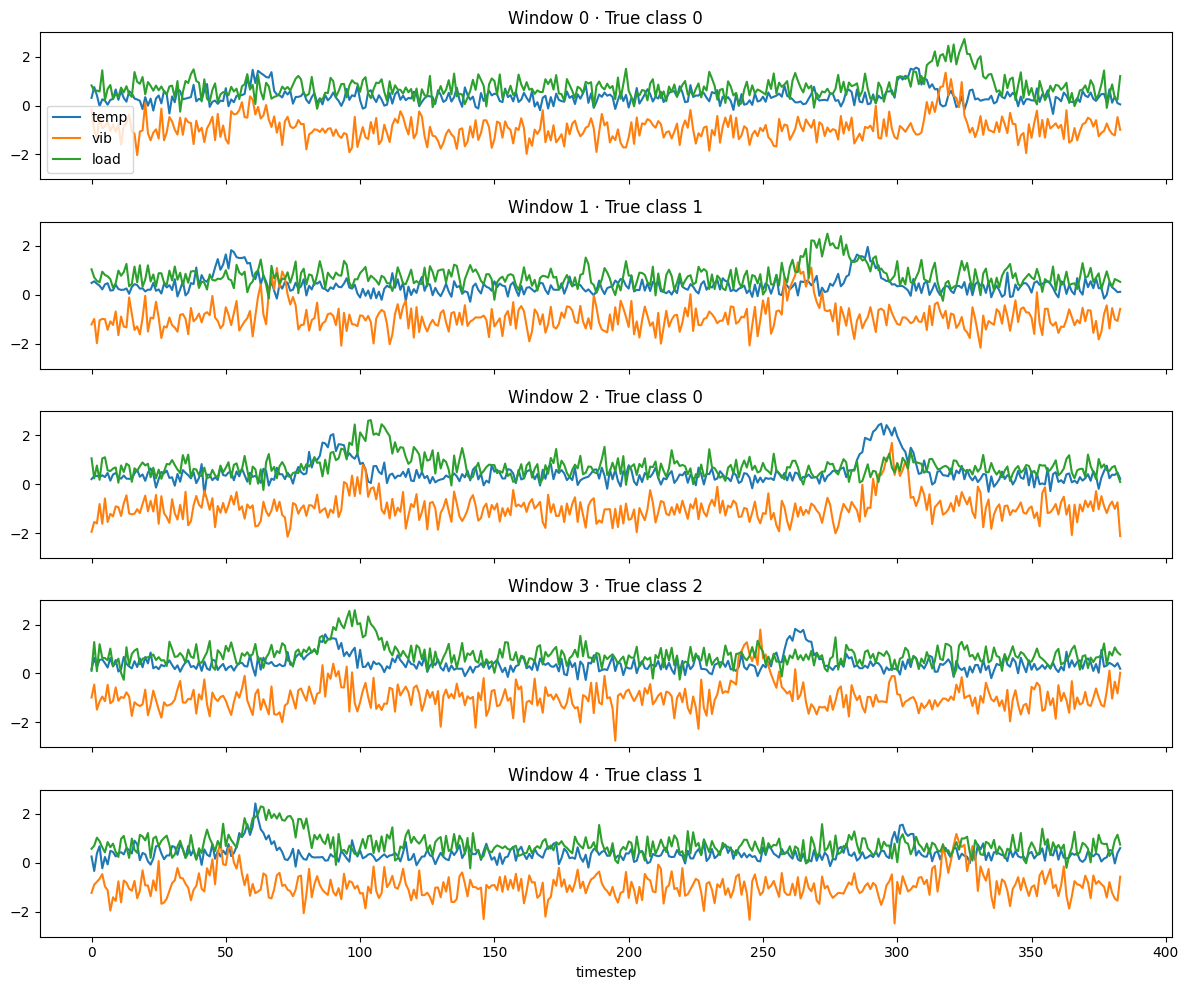

In [ ]:
# @title
fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True, sharey=True)
timesteps = torch.arange(X_train.size(1))
sensor_names = ["temp", "vib", "load"]

for i, ax in enumerate(axes):
    for channel, name in enumerate(sensor_names):
        ax.plot(timesteps, X_train[i, :, channel], label=name)

    ax.set_title(f"Window {i} · True class {y_train[i].item()}")

axes[0].legend()
axes[-1].set_xlabel("timestep")
fig.tight_layout()
plt.show()

Baseline validation macro F1: 0.9519
                 precision    recall  f1-score   support

     Temp first     0.9293    0.9989    0.9628       881
Vibration first     0.9384    1.0000    0.9682       822
 Within 3 steps     1.0000    0.8600    0.9247       857

       accuracy                         0.9527      2560
      macro avg     0.9559    0.9529    0.9519      2560
   weighted avg     0.9559    0.9527    0.9518      2560



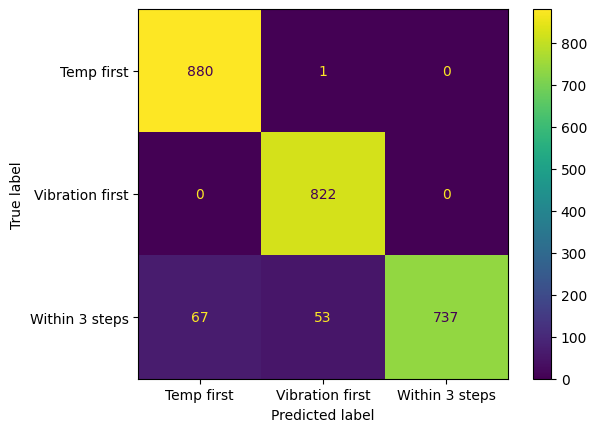

In [ ]:
## THIS FUNC IS IMPORTANT, REMEMBER SYNTAX
def crop_marked_half(windows):
    # windows: [N, 384, 3]
    midpoint = windows.size(1) // 2
    load = windows[:, :, 2]

    load_avg = load.unfold(1, 9, 1).mean(dim=-1)
    # print(load_avg.shape)
    load_center = load_avg.argmax(dim=1) + 4
    is_late = load_center >= midpoint

    return torch.where(
        is_late[:, None, None],
        windows[:, midpoint:, :],
        windows[:, :midpoint, :],
    )


def pred_baseline(cropped_windows):
    # [N, 192, 2] -> [N, 184, 2, 9] -> [N, 184, 2]
    averages = cropped_windows[:, :, :2].unfold(1, 9, 1).mean(dim=-1)
    peaks = averages.argmax(dim=1)

    temp_peak = peaks[:, 0]
    vib_peak = peaks[:, 1]
    gap = vib_peak - temp_peak

    # 0 = temp first, 1 = vib first, 2 = within 3 steps.
    predictions = (gap < 0).long()
    predictions[gap.abs() <= 3] = 2
    return predictions


train_crops = crop_marked_half(X_train.to(device)).cpu()
val_crops = crop_marked_half(X_val.to(device)).cpu()

class_ids = [0, 1, 2]
class_names = ["Temp first", "Vibration first", "Within 3 steps"]

predicted = pred_baseline(val_crops)
baseline_f1 = f1_score(y_val, predicted, labels=class_ids, average="macro")
print(f"Baseline validation macro F1: {baseline_f1:.4f}")
print(classification_report(
    y_val, predicted, labels=class_ids, target_names=class_names, digits=4
))

cm = confusion_matrix(y_val, predicted, labels=class_ids)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
fig.tight_layout()
plt.show()

In [ ]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Give the training loader its own reproducible shuffle sequence.
shuffle_generator = torch.Generator().manual_seed(SEED)

In [ ]:
# Conv1d expects [batch, channels, timesteps].
X_tr = train_crops.transpose(1, 2)
X_va = val_crops.transpose(1, 2)

dataset = TensorDataset(X_tr, y_train.long())
loader = DataLoader(dataset, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEED))

val_dataset = TensorDataset(X_va, y_val.long())
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, generator=torch.Generator().manual_seed(SEED))

def build_model():
  model = nn.Sequential(
      nn.Conv1d(3, 16, kernel_size=9, stride=1, padding=4),
      nn.ReLU(),
      nn.Conv1d(16, 16, kernel_size=9, stride=1, padding=4),
      nn.ReLU(),
      nn.Conv1d(16, 16, kernel_size=9, stride=1, padding=4),
      nn.ReLU(),
      nn.Conv1d(16, 16, kernel_size=9, stride=1, padding=4),
      nn.ReLU(),
      nn.AdaptiveAvgPool1d(output_size=8),
      nn.Flatten(),
      nn.Linear(16 * 8, 3),
  ).to(device)
  return model

In [ ]:
from sklearn.metrics import f1_score

def eval_model(model):
  y_pred = []
  y_t = []
  f1 = None

  with torch.inference_mode():
    val_loss = 0
    model.eval()
    for inputs, target in val_loader:
      inputs = inputs.to(device)
      target = target.to(device)

      logits = model(inputs)
      loss = loss_func(logits, target)

      y_p = logits.argmax(dim=1)
      y_pred.append(y_p.cpu())
      y_t.append(target.cpu())

      val_loss += loss.item() * target.size(0)


    val_loss /= len(val_dataset)
    f1 = f1_score(torch.cat(y_t), torch.cat(y_pred), average="macro")

    return val_loss, f1, y_t, y_pred


In [ ]:
epochs = 50
total_loss = 0

best_val = float("inf")
best_epoch = 0
best_lr = None
best_state = None
best_mf1 = float("-inf")

lr = [3e-4, 1e-3, 3e-3]
loss_func = nn.CrossEntropyLoss()


for rate in lr:
  print(f"new lr: {rate}")
  torch.manual_seed(SEED)
  torch.Generator().manual_seed(SEED)
  model = build_model()
  optimizer = torch.optim.AdamW(model.parameters(), lr=rate)

  for i in range(epochs):
    model.train()
    epoch_loss = 0
    for inputs, targets in loader:
      inputs = inputs.to(device)
      targets = targets.to(device)

      optimizer.zero_grad()
      logits = model(inputs)
      loss = loss_func(logits, targets)
      loss.backward()
      optimizer.step()
      epoch_loss += loss.item() * targets.size(0)

    val_loss, f1, _, _ = eval_model(model)
    if f1 > best_mf1:
      best_mf1 = f1
      best_epoch = i
      best_val = val_loss
      best_lr = rate
      best_state = deepcopy(model.state_dict())

      # print(model.state_dict().keys())


    print(f"epoch loss: {epoch_loss/len(dataset)}")
  print(f"="*30)

new lr: 0.0003
epoch loss: 1.0201547807082534
epoch loss: 0.7270135530270636
epoch loss: 0.5386432770173997
epoch loss: 0.4060059441253543
epoch loss: 0.32957894149391603
epoch loss: 0.2800635405583307
epoch loss: 0.25605441893761355
epoch loss: 0.23600141923331344
epoch loss: 0.2192627725598868
epoch loss: 0.21203031473366232
epoch loss: 0.19148751992421845
epoch loss: 0.18374277264229022
epoch loss: 0.1685244640490661
epoch loss: 0.15511540189618245
epoch loss: 0.13356871377133453
epoch loss: 0.12063621342046342
epoch loss: 0.10757299069518922
epoch loss: 0.0934170583083566
epoch loss: 0.08329815641627647
epoch loss: 0.08027864753845886
epoch loss: 0.0696961704112861
epoch loss: 0.05993486921033764
epoch loss: 0.05823788772492359
epoch loss: 0.05402352658650974
epoch loss: 0.051404611227856854
epoch loss: 0.04843403405387411
epoch loss: 0.045530226464658576
epoch loss: 0.04844757500177366
epoch loss: 0.04164138742332094
epoch loss: 0.037489894241237685
epoch loss: 0.03815892087701892

In [ ]:
print(f"best lr: {best_lr}")
print(f"best epoch: {best_epoch}")

model.load_state_dict(best_state)
val_loss, f1, y_t, y_pred = eval_model(model)

print(val_loss)

best lr: 0.001
best epoch: 47
0.01601146644532605


macro f1: 0.9961223239597382
val loss: 0.01601146644532605


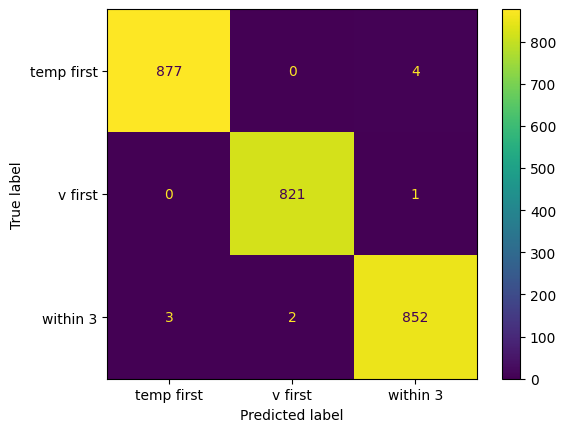

In [ ]:
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

f1 = f1_score(torch.cat(y_t), torch.cat(y_pred), average="macro")

print(f"macro f1: {f1}")
print(f"val loss: {val_loss}")

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(torch.cat(y_t), torch.cat(y_pred), labels=[0, 1, 2])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["temp first", "v first", "within 3"]).plot()
plt.show()